In [ ]:
import torch
import pandas as pd
import torch.nn.functional as F

In [38]:
df_relaxase = pd.read_csv("../data/processed/relaxase_oriT_dataset.csv")

df_rep = pd.read_csv("../data/processed/final_rep_virus_dataset.csv")

In [39]:
df_rep = df_rep[df_rep['match'] == 'Yes']

df_rep = df_rep.drop(columns=['taxid', 'virus_name', 'sDBM_sim_gap', 'ori_align_score', 'iteration_name', 'match'])

df_rep = df_rep.drop_duplicates(subset=["sDBM", "ori_seq"], keep='first')

df_rep.to_csv('../data/processed/unique_rep_oriR_dataset.csv', index=False)

df_rep

,sDBM_pos,sDBM,ori_seq,rep_amino_acid_seq
0,"(63, 71)",GAHFEKRRG,TAGTATTAC,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...
1,"(63, 71)",GAHLEKRKG,TATTATTAC,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...
2,"(73, 81)",KPHLEKQRA,GACTGCTAC,MAAIKGQWWCFTVFFLTATAPDLVPLFENTHVSYACWQEEESPTTK...
3,"(70, 78)",RAHWEKARG,TAGTATTAC,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...
4,"(74, 82)",RAHFECAKG,CAGTATTAC,MAPRGNAAKRWTFTINNWTLADYDKVLEFTTKFEPVFLICGKERGE...
...,...,...,...,...
245,"(64, 72)",QAHIEESNH,TAGTAATAC,MKVYLITAPRSTPKKALKIMIEKNDCKKWIIGWEKGKNGYEHFQIR...
246,"(64, 72)",AAHIEEAQQ,CATTTGTAC,MKKYIMTVPRSVPKKALKIMIDVNDCKKWIIGKERGKNGYEHWQIR...
247,"(63, 71)",GWHVEDCVS,CAGTATTAC,MKYVATIPRDGIKESQLVRLLQTLDLHEAYLGREIGDGGYRHYQCA...
248,"(72, 80)",RAHWEPRRG,TAGTATTAC,MEHRKGRGTFSKDWVFTLNNYNEEDKELIEGIDCQYVIYGKEVGEN...


In [ ]:
def make_position_class_weights(df, sequence_col=2):
    bases = "ACGT"
    counts = torch.zeros((9, 4), dtype=torch.float32)

    for sequence in df.iloc[:, sequence_col].astype(str).str.upper():
        if len(sequence) != 9 or any(base not in bases for base in sequence):
            raise ValueError(f"Invalid 9-mer: {sequence!r}")

        for position, base in enumerate(sequence):
            counts[position, bases.index(base)] += 1

    # Inverse frequency per position, normalized to mean 1 over observed classes.
    weights = torch.zeros_like(counts)
    present = counts > 0

    # Softer than inverse frequency -> inverse square root of frequency
    weights[present] = counts[present].rsqrt()

    # Normalize across column
    weights *= present.sum(dim=1, keepdim=True) / weights.sum(dim=1, keepdim=True)

    return weights

    return weights  # shape: [9, 4]


rep_position_weights = make_position_class_weights(df_rep)

In [4]:
df_relaxase = df_relaxase.dropna(subset=['oriT_nic_seq'])

# remember to set sDBM threshold

df_relaxase = df_relaxase.drop(columns=['oriTDB_accession', 'oriTDB_id', 'nic site', 'sDBM_sim_gap'])

df_relaxase = df_relaxase.drop_duplicates(subset=["sDBM", "oriT_nic_seq"], keep='first')

df_relaxase

,relaxase_family,relaxase_sequence,host,sDBM,sDBM_pos,oriT_nic_seq
0,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Pseudomonas aeruginosa,HVPMRSIKK,"(4, 12)",TATCCTGCC
2,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,Escherichia coli,HLTAKTGSR,"(4, 12)",AAGTGCGCC
3,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)",TATCCTGCA
5,TraA,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...,Streptococcus agalactiae B-49813/75,IAKRENGKR,"(2, 10)",AAGTGCGCC
6,TraI,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...,Salmonella typhi,SISSIKGDA,"(2, 10)",CGGGTGTGG
...,...,...,...,...,...,...
1336,Relaxase_PUP23_RS00120,MRNVKKSSFVELAKYLQDPQSKQERVGVIKVTNCHQENILDAARYD...,Escherichia coli strain LA172,VELAKYLQD,"(9, 17)",TGTCCTGCC
1371,Mob_Pre_PU712_RS19420,MGTVAAALQHCYRDRETPNADQERTPDNDHLAARSTDEAMGKLRER...,Proteus mirabilis strain CY32,AAALQHCYR,"(4, 12)",AAGTGCGCC
1376,MobF,MVLTRQDIGRAASYYEDGADDYYAKDGDASEWQGKGAEELGLSGEV...,Enterobacter hormaechei strain TUM10660,VLTRQDIGR,"(1, 9)",ATTGTCTAT
1379,Rep_trans_F1621_RS12210_SESURV_p2,MYSNSRLSGQTLGKSQPELSFDAMTIVGNLNKNNAQKLSEFMSVEP...,Staphylococcus epidermidis strain SESURV_p2_0614,TIVGNLNKN,"(24, 32)",TCGATTGGT


In [69]:
df_new_relaxase = df_relaxase.drop(columns=['relaxase_family', 'host'])

#reorder
df_new_relaxase = df_new_relaxase[["sDBM_pos", "sDBM", "oriT_nic_seq", "relaxase_sequence"]]

df_new_relaxase.to_csv('../data/processed/unique_relaxase_oriT_dataset.csv', index=False)

df_new_relaxase

,sDBM_pos,sDBM,oriT_nic_seq,relaxase_sequence
0,"(4, 12)",HVPMRSIKK,TATCCTGCC,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...
2,"(4, 12)",HLTAKTGSR,AAGTGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
3,"(4, 12)",VEKDYRVKR,TATCCTGCA,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...
5,"(2, 10)",IAKRENGKR,AAGTGCGCC,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...
6,"(2, 10)",SISSIKGDA,CGGGTGTGG,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...
...,...,...,...,...
1336,"(9, 17)",VELAKYLQD,TGTCCTGCC,MRNVKKSSFVELAKYLQDPQSKQERVGVIKVTNCHQENILDAARYD...
1371,"(4, 12)",AAALQHCYR,AAGTGCGCC,MGTVAAALQHCYRDRETPNADQERTPDNDHLAARSTDEAMGKLRER...
1376,"(1, 9)",VLTRQDIGR,ATTGTCTAT,MVLTRQDIGRAASYYEDGADDYYAKDGDASEWQGKGAEELGLSGEV...
1379,"(24, 32)",TIVGNLNKN,TCGATTGGT,MYSNSRLSGQTLGKSQPELSFDAMTIVGNLNKNNAQKLSEFMSVEP...


In [74]:
# relaxase

count_minus7 = {}
count_minus6 = {}
count_minus5 = {}
count_minus4 = {}
count_minus3 = {}
count_minus2 = {}
count_minus1 = {}
count_plus1 = {}
count_plus2 = {}

count_dicts = [
    count_minus7,
    count_minus6,
    count_minus5,
    count_minus4,
    count_minus3,
    count_minus2,
    count_minus1,
    count_plus1,
    count_plus2,
]


def count_bases(row):
    oriT_seq = row["oriT_nic_seq"]

    for i, base in enumerate(oriT_seq[:9]):
        count_dicts[i][base] = count_dicts[i].get(base, 0) + 1


df_new_relaxase.apply(count_bases, axis = 1)

base_counts = pd.DataFrame(
    count_dicts,
    index=["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]
).fillna(0).astype(int)

print(base_counts)

base_freq = base_counts.div(base_counts.sum(axis=1), axis=0)

print(base_freq)

      T    A    C    G
-7   78   62   38   34
-6   41  112   16   43
-5   78   32   10   92
-4   47    9  108   48
-3  105    4   54   49
-2   95    9   23   85
-1   43    5    9  155
+1   48   16  109   39
+2   76   31   70   35
           T         A         C         G
-7  0.367925  0.292453  0.179245  0.160377
-6  0.193396  0.528302  0.075472  0.202830
-5  0.367925  0.150943  0.047170  0.433962
-4  0.221698  0.042453  0.509434  0.226415
-3  0.495283  0.018868  0.254717  0.231132
-2  0.448113  0.042453  0.108491  0.400943
-1  0.202830  0.023585  0.042453  0.731132
+1  0.226415  0.075472  0.514151  0.183962
+2  0.358491  0.146226  0.330189  0.165094


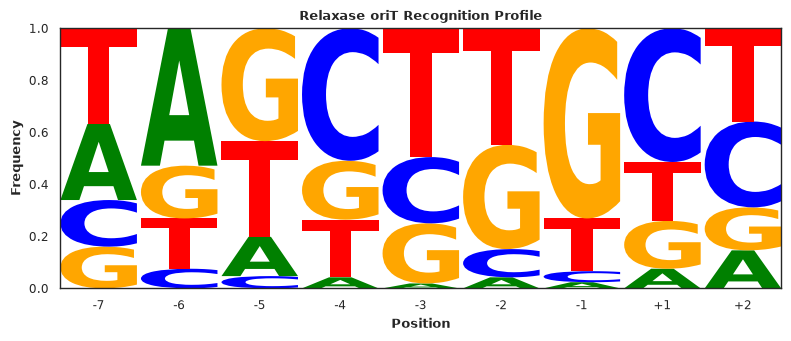

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import logomaker

weighted_matrix = pd.DataFrame(
    count_dicts,
    index=range(9),
).fillna(0)

weighted_matrix = weighted_matrix[["A", "C", "G", "T"]]
weighted_matrix = weighted_matrix.div(
    weighted_matrix.sum(axis=1).replace(0, 1),
    axis=0,
)

custom_labels = ["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]

fig, ax = plt.subplots(figsize=(8, 3.5))

logo = logomaker.Logo(
    weighted_matrix,
    ax=ax,
    color_scheme="classic",
)

ax.set_title("Relaxase oriT Recognition Profile", weight="bold")
ax.set_xlabel("Position")
ax.set_ylabel("Frequency")
ax.set_xticks(range(len(custom_labels)))
ax.set_xticklabels(custom_labels)

fig.tight_layout()
plt.show()

In [77]:
# rep

count_minus7 = {}
count_minus6 = {}
count_minus5 = {}
count_minus4 = {}
count_minus3 = {}
count_minus2 = {}
count_minus1 = {}
count_plus1 = {}
count_plus2 = {}

count_dicts = [
    count_minus7,
    count_minus6,
    count_minus5,
    count_minus4,
    count_minus3,
    count_minus2,
    count_minus1,
    count_plus1,
    count_plus2,
]


def count_bases(row):
    oriT_seq = row["ori_seq"]

    for i, base in enumerate(oriT_seq[:9]):
        count_dicts[i][base] = count_dicts[i].get(base, 0) + 1


df_rep.apply(count_bases, axis = 1)

base_counts = pd.DataFrame(
    count_dicts,
    index=["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]
).fillna(0).astype(int)

print(base_counts)

base_freq = base_counts.div(base_counts.sum(axis=1), axis=0)

print(base_freq)

      T   G    C    A
-7  146  12   38   33
-6   10   4    5  210
-5   32  97   13   87
-4  218   0    6    5
-3   34  31   20  144
-2  152   9   44   24
-1  214   6    6    3
+1    0   0    0  229
+2    0   0  229    0
           T         G         C         A
-7  0.637555  0.052402  0.165939  0.144105
-6  0.043668  0.017467  0.021834  0.917031
-5  0.139738  0.423581  0.056769  0.379913
-4  0.951965  0.000000  0.026201  0.021834
-3  0.148472  0.135371  0.087336  0.628821
-2  0.663755  0.039301  0.192140  0.104803
-1  0.934498  0.026201  0.026201  0.013100
+1  0.000000  0.000000  0.000000  1.000000
+2  0.000000  0.000000  1.000000  0.000000


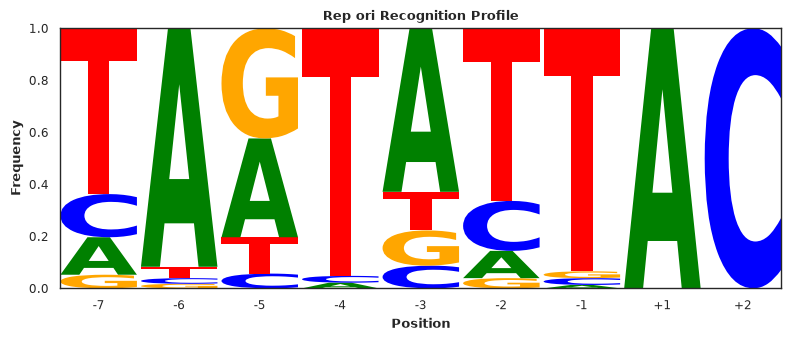

In [80]:
import pandas as pd
import matplotlib.pyplot as plt
import logomaker

weighted_matrix = pd.DataFrame(
    count_dicts,
    index=range(9),
).fillna(0)

weighted_matrix = weighted_matrix[["A", "C", "G", "T"]]
weighted_matrix = weighted_matrix.div(
    weighted_matrix.sum(axis=1).replace(0, 1),
    axis=0,
)

custom_labels = ["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]

fig, ax = plt.subplots(figsize=(8, 3.5))

logo = logomaker.Logo(
    weighted_matrix,
    ax=ax,
    color_scheme="classic",
)

ax.set_title("Rep ori Recognition Profile", weight="bold")
ax.set_xlabel("Position")
ax.set_ylabel("Frequency")
ax.set_xticks(range(len(custom_labels)))
ax.set_xticklabels(custom_labels)

fig.tight_layout()
plt.show()

In [5]:
df_new_relaxase = pd.read_csv("../data/processed/unique_relaxase_oriT_dataset.csv")

df_new_rep = pd.read_csv("../data/processed/unique_rep_oriR_dataset.csv")

df_new_rep.rename(columns={"sDBM_pos": "sDBM_pos", "sDBM": "sDBM", "ori_seq": "ori_nic_seq", "rep_amino_acid_seq": "amino_acid_seq"}, inplace=True)
df_new_relaxase.rename(columns={"sDBM_pos": "sDBM_pos", "sDBM": "sDBM", "oriT_nic_seq": "ori_nic_seq", "relaxase_sequence": "amino_acid_seq"}, inplace=True)

df = pd.concat([df_new_relaxase, df_new_rep], ignore_index=True)

df

,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq
0,"(4, 12)",HVPMRSIKK,TATCCTGCC,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...
1,"(4, 12)",HLTAKTGSR,AAGTGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
2,"(4, 12)",VEKDYRVKR,TATCCTGCA,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...
3,"(2, 10)",IAKRENGKR,AAGTGCGCC,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...
4,"(2, 10)",SISSIKGDA,CGGGTGTGG,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...
...,...,...,...,...
436,"(64, 72)",QAHIEESNH,TAGTAATAC,MKVYLITAPRSTPKKALKIMIEKNDCKKWIIGWEKGKNGYEHFQIR...
437,"(64, 72)",AAHIEEAQQ,CATTTGTAC,MKKYIMTVPRSVPKKALKIMIDVNDCKKWIIGKERGKNGYEHWQIR...
438,"(63, 71)",GWHVEDCVS,CAGTATTAC,MKYVATIPRDGIKESQLVRLLQTLDLHEAYLGREIGDGGYRHYQCA...
439,"(72, 80)",RAHWEPRRG,TAGTATTAC,MEHRKGRGTFSKDWVFTLNNYNEEDKELIEGIDCQYVIYGKEVGEN...


In [10]:
def get_dna_encoding(ori_seq):

    dna_vec_list = []

    for base in ori_seq:
        match base:
            case 'A':
                dna_vec_list.append(0)
            case 'C':
                dna_vec_list.append(1)
            case 'G':
                dna_vec_list.append(2)
            case 'T':  
                dna_vec_list.append(3)

    #convert to tensor
    dna_encoding = torch.tensor(dna_vec_list, dtype=torch.long)

    return dna_encoding

In [129]:
X_rep = torch.load("../data/embeddings/ori_predictor_separate/X_rep.pt")
y_rep = torch.load("../data/embeddings/ori_predictor_separate/y_rep.pt")

X_relax = torch.load("../data/embeddings/ori_predictor_separate/X_relax.pt")
y_relax = torch.load("../data/embeddings/ori_predictor_separate/y_relax.pt")

In [130]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split


class CustomDataset(Dataset):
    # required dunder methods
    def __init__(self, data, target):
        self.data = torch.tensor(data, dtype = torch.float32)
        self.target = torch.tensor(target, dtype=torch.long)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample_x = self.data[index] #instead of tensor(self.data) -> avoid UserWarning
        sample_y = self.target[index]

        return sample_x, sample_y


In [ ]:
full_dataset = CustomDataset(X_relax, y_relax) #CHANGE to get rep and relax only

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

print(f"Training Set: {train_size}")
print(f"Validation Set: {val_size}")  

train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

x_val_dataset = torch.stack([val_dataset[i][0] for i in range(len(val_dataset))])
y_val_dataset = torch.stack([val_dataset[i][1] for i in range(len(val_dataset))])

train_dataloader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)

print(x_val_dataset.shape)

Training Set: 169
Validation Set: 43
torch.Size([43, 383])


/tmp/ipykernel_22461/3740502985.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, dtype = torch.float32)
/tmp/ipykernel_22461/3740502985.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.target = torch.tensor(target, dtype=torch.long)


In [116]:
# for separate rep and relax validation
X_train = torch.load("../data/embeddings/ori_predictor_combined/combined_X_train.pt")
y_train = torch.load("../data/embeddings/ori_predictor_combined/combined_y_train.pt")
X_val_rep = torch.load("../data/embeddings/ori_predictor_combined/X_val_rep.pt")
y_val_rep = torch.load("../data/embeddings/ori_predictor_combined/y_val_rep.pt")
X_val_relax = torch.load("../data/embeddings/ori_predictor_combined/X_val_relax.pt")
y_val_relax = torch.load("../data/embeddings/ori_predictor_combined/y_val_relax.pt")

combined_train_dataset = CustomDataset(X_train, y_train)

train_dataloader = DataLoader(dataset=combined_train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
x_val_rep_set = X_val_rep
y_val_rep_set = y_val_rep
x_val_relax_set = X_val_relax
y_val_relax_set = y_val_relax

#concat for running stat
x_val_dataset = torch.concat([x_val_rep_set, x_val_relax_set], dim=0)
y_val_dataset = torch.concat([y_val_rep_set, y_val_relax_set], dim=0)

perm_val = torch.randperm(len(x_val_dataset))
x_val_dataset = x_val_dataset[perm_val]
y_val_dataset = y_val_dataset[perm_val]

print(X_train.shape) 

torch.Size([341, 397])


/tmp/ipykernel_22461/3740502985.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, dtype = torch.float32)
/tmp/ipykernel_22461/3740502985.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.target = torch.tensor(target, dtype=torch.long)


Machine Learning

In [132]:
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [150]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class MultiHeadFourClassClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        #initialise nn.Module parent class constructor
        super().__init__()

        # self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        # self.relu = nn.ReLU()
        # self.dropout = nn.Dropout(p=0.3)
        # self.fc2 = nn.Linear(in_features=hidden_dim, out_features=9)

        self.shared_backbone = nn.Linear(in_features=input_dim, out_features=hidden_dim)

        self.relu = nn.ReLU()

        self.heads = nn.ModuleList([nn.Linear(hidden_dim, 4) for _ in range(9)])

    def forward(self, x):

        # returns -> 9, B, 4 ?

        # x = self.relu(self.fc1(x))
        # x = self.dropout(x)
        # return self.fc2(x)
        x = self.relu(self.shared_backbone(x))
        x = [head(x) for head in self.heads]
        return x

In [157]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class MultiHeadFourClassClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2):
        #initialise nn.Module parent class constructor
        super().__init__()

        # self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        # self.relu = nn.ReLU()
        # self.dropout = nn.Dropout(p=0.3)
        # self.fc2 = nn.Linear(in_features=hidden_dim, out_features=9)

        self.shared_backbone1 = nn.Linear(in_features=input_dim, out_features=hidden_dim1)

        self.shared_backbone2 = nn.Linear(in_features=hidden_dim1, out_features=hidden_dim2)

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(p=0.3)

        self.heads = nn.ModuleList([nn.Linear(hidden_dim2, 4) for _ in range(9)])

    def forward(self, x):

        # returns -> 9, B, 4 ?

        # x = self.relu(self.fc1(x))
        # x = self.dropout(x)
        # return self.fc2(x)
        x = self.relu(self.shared_backbone1(x))
        x = self.dropout(x)
        x = self.relu(self.shared_backbone2(x))
        x = self.dropout(x)
        x = [head(x) for head in self.heads]
        return x

In [151]:
class PositionWeightedCrossEntropy(nn.Module):
    def __init__(self, position_class_weights):
        super().__init__()
        # Stored as a buffer, so it follows loss_fn.to(device).
        self.register_buffer(
            "position_class_weights",
            position_class_weights.float(),
        )

    def forward(self, logits, targets):
        # logits: [B, 4, 9]; targets: [B, 9]
        targets = targets.long()

        per_position_loss = F.cross_entropy(
            logits,
            targets,
            reduction="none",
        )  # [B, 9]

        # Select the weight matching each target base at each position.
        weights = self.position_class_weights.T  # [4, 9]
        target_weights = weights[targets, torch.arange(9, device=targets.device)]

        return (per_position_loss * target_weights).sum() / target_weights.sum().clamp_min(1e-12)

In [161]:
#oriT_predictor = MultiHeadFourClassClassiferNN(194, 64).to(device)
#oriT_predictor = MultiHeadFourClassClassiferNN(102, 92, 64).to(device)
oriT_predictor = MultiHeadFourClassClassiferNN(383, 64, 64).to(device)
#oriT_predictor = MultiHeadFourClassClassiferNN(383, 64).to(device)

#oriT_predictor = MultiHeadFourClassClassiferNN(35, 92, 64).to(device)


oriT_predictor.state_dict() # random parameters before training
next(oriT_predictor.parameters()).device

# set up the loss function
loss_fn = nn.CrossEntropyLoss() #interally applies softmax
#loss_fn = PositionWeightedCrossEntropy(rep_position_weights).to(device)

# 0.001 worked well
optimiser = torch.optim.Adam(oriT_predictor.parameters(), lr=0.001, weight_decay=1e-4) #0.001

def accuracy_fn(y_true, y_pred):
    pass

    correct_pred = torch.eq(y_true, y_pred).sum().item()
    total_pred = y_true.numel() #across all batches (over 9 positions)

    accuracy = (correct_pred/total_pred) * 100

    return accuracy

In [ ]:
print(x_val_dataset.shape)

torch.manual_seed(3242)

epochs = 30

acc = []
acc_val = []

loss_train = []
loss_val = []

for epoch in range(epochs):

    # Training
    oriT_predictor.train()

    running_loss = 0.0
    running_acc = 0.0

    for batch_idx, (inputs, targets) in enumerate(train_dataloader):

        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)


        y_logits = torch.stack(oriT_predictor(inputs), dim = 0) #convert [] -> tensor along extra dimension
        y_logits_permuted = y_logits.permute(1, 2, 0) #permute tensor to B, C, 9


        y_pred = torch.argmax(y_logits_permuted, dim = 1)


        accuracy = accuracy_fn(targets, y_pred)

        # CrossEntropyLoss expects logits directly (no softmax)
        loss = loss_fn(y_logits_permuted, targets)

        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        # Accumulate metrics
        running_loss += loss.item()
        running_acc += accuracy


    # Average training metrics
    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)


    # Validation 
    oriT_predictor.eval()

    with torch.inference_mode():

        test_inputs = x_val_dataset.to(device, non_blocking=True)
        test_targets = y_val_dataset.to(device, non_blocking=True)

        test_logits = torch.stack(oriT_predictor(test_inputs), dim = 0) #convert [] -> tensor along extra dimension
        test_logits_permuted = test_logits.permute(1, 2, 0) #permute tensor to B, C, 9

        test_pred = torch.argmax(test_logits_permuted, dim = 1)

        test_loss = loss_fn(test_logits_permuted, test_targets)

        test_accuracy = accuracy_fn(test_targets, test_pred)



    # print
    if (epoch + 1) % 1 == 0:

        acc.append(epoch_acc)
        acc_val.append(test_accuracy)
        loss_train.append(epoch_loss)
        loss_val.append(test_loss.item())

        print(
            f"Epoch: {epoch+1:02d}/{epochs} | "
            f"Training Loss: {epoch_loss:.4f} | "
            f"Training Accuracy: {epoch_acc:.4f} | "
            f"Test Loss: {test_loss.item():.4f} | "
            f"Test Accuracy: {test_accuracy:.4f}"
        )

torch.Size([43, 383])
Epoch: 01/30 | Training Loss: 1.3948 | Training Accuracy: 33.2369 | Test Loss: 1.2742 | Test Accuracy: 43.6693
Epoch: 02/30 | Training Loss: 1.2055 | Training Accuracy: 42.9462 | Test Loss: 1.1461 | Test Accuracy: 56.0724
Epoch: 03/30 | Training Loss: 1.0925 | Training Accuracy: 53.6394 | Test Loss: 1.0450 | Test Accuracy: 61.4987
Epoch: 04/30 | Training Loss: 1.0261 | Training Accuracy: 58.8349 | Test Loss: 0.9778 | Test Accuracy: 64.5995
Epoch: 05/30 | Training Loss: 0.9329 | Training Accuracy: 62.9630 | Test Loss: 0.9328 | Test Accuracy: 64.8579
Epoch: 06/30 | Training Loss: 0.8242 | Training Accuracy: 67.0653 | Test Loss: 0.9059 | Test Accuracy: 66.4083
Epoch: 07/30 | Training Loss: 0.8146 | Training Accuracy: 67.8948 | Test Loss: 0.8893 | Test Accuracy: 65.8915
Epoch: 08/30 | Training Loss: 0.7471 | Training Accuracy: 72.0615 | Test Loss: 0.8813 | Test Accuracy: 65.8915
Epoch: 09/30 | Training Loss: 0.7353 | Training Accuracy: 71.7657 | Test Loss: 0.8780 | Te

In [68]:
from sklearn.metrics import f1_score

oriT_predictor.eval()

with torch.inference_mode():
    test_inputs = x_val_dataset.to(device, non_blocking=True)
    test_targets = y_val_dataset.to(device, non_blocking=True)

    head_logits = oriT_predictor(test_inputs)
    predictions = torch.stack(
        [logits.argmax(dim=1) for logits in head_logits],
        dim=1,
    )

weighted_f1 = f1_score(
    test_targets.cpu().numpy().reshape(-1),
    predictions.cpu().numpy().reshape(-1),
    average="weighted",
)

print(f"Validation weighted F1 score: {weighted_f1:.4f}")

Validation weighted F1 score: 0.7756


In [163]:
from sklearn.metrics import f1_score

oriT_predictor.eval()

with torch.inference_mode():
    test_inputs = x_val_dataset.to(device, non_blocking=True)
    test_targets = y_val_dataset.to(device, non_blocking=True)

    head_logits = oriT_predictor(test_inputs)
    logits = torch.stack(head_logits, dim=2)  # (samples, classes, positions)
    predictions = logits.argmax(dim=1)       # (samples, positions)

    y_true = test_targets.cpu().numpy().reshape(-1)
    y_pred = predictions.cpu().numpy().reshape(-1)

    overall_accuracy = (y_pred == y_true).mean() * 100
    f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

print(f"Validation accuracy: {overall_accuracy:.2f}%")
print(f"Validation weighted F1: {f1_weighted:.4f}")
print(f"Validation macro F1: {f1_macro:.4f}")

Validation accuracy: 69.77%
Validation weighted F1: 0.6983
Validation macro F1: 0.7027


In [140]:
from sklearn.metrics import precision_score
import numpy as np

# y_true and y_pred have shape (samples, heads)
y_true = test_targets.cpu().numpy()
y_pred = predictions.cpu().numpy()

# Macro precision for each head (averages class precision within that head)
precision_per_head = [
    precision_score(
        y_true[:, head],
        y_pred[:, head],
        average="macro",
        zero_division=0,
    )
    for head in range(y_true.shape[1])
]

# Overall macro precision across all head-position predictions
overall_macro_precision = precision_score(
    y_true.reshape(-1),
    y_pred.reshape(-1),
    average="macro",
    zero_division=0,
)

for head, precision in enumerate(precision_per_head, start=1):
    print(f"Head {head} macro precision: {precision:.4f}")

print(f"Overall macro precision: {overall_macro_precision:.4f}")

ValueError: Found input variables with inconsistent numbers of samples: [46, 43]

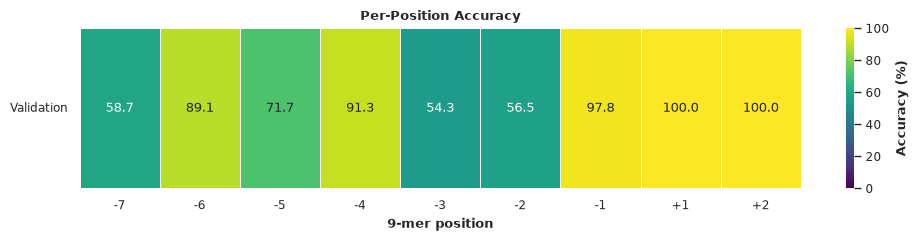

In [147]:
import seaborn as sns
import matplotlib.pyplot as plt

x_val_dataset = torch.stack(
    [val_dataset[i][0] for i in range(len(val_dataset))]
)
y_val_dataset = torch.stack(
    [val_dataset[i][1] for i in range(len(val_dataset))]
)

oriT_predictor.eval()

with torch.inference_mode():
    inputs = x_val_dataset.to(device, non_blocking=True)
    targets = y_val_dataset.to(device, non_blocking=True)

    head_logits = oriT_predictor(inputs)
    predictions = torch.stack(
        [logits.argmax(dim=1) for logits in head_logits],
        dim=1,
    )

    head_accuracies = (
        predictions.eq(targets).float().mean(dim=0).cpu().numpy() * 100
    )

accuracy_df = pd.DataFrame(
    [head_accuracies],
    index=["Validation"],
    columns=["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"],
)

sns.set_theme(style="white", font="DejaVu Sans", context="paper")
fig, ax = plt.subplots(figsize=(10, 2.5))

sns.heatmap(
    accuracy_df,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="viridis",
    vmin=0,
    vmax=100,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Accuracy (%)"},
)

ax.set_xlabel("9-mer position")
ax.set_ylabel("")
ax.set_title("Per-Position Accuracy")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
plt.show()

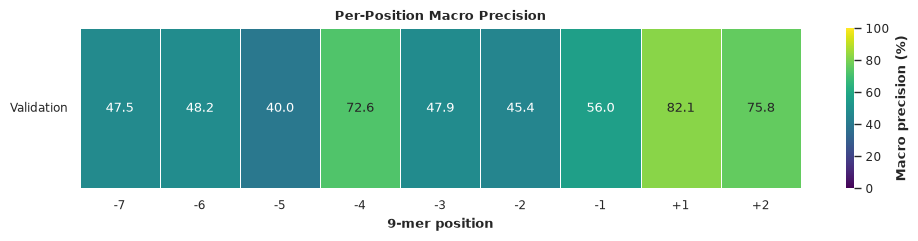

In [164]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score

x_val_dataset = torch.stack(
    [val_dataset[i][0] for i in range(len(val_dataset))]
)
y_val_dataset = torch.stack(
    [val_dataset[i][1] for i in range(len(val_dataset))]
)

oriT_predictor.eval()

with torch.inference_mode():
    inputs = x_val_dataset.to(device, non_blocking=True)
    targets = y_val_dataset.to(device, non_blocking=True)

    head_logits = oriT_predictor(inputs)
    predictions = torch.stack(
        [logits.argmax(dim=1) for logits in head_logits],
        dim=1,
    )

# Calculate macro precision independently for each position/head.
pred_np = predictions.cpu().numpy()
targets_np = targets.cpu().numpy()

head_macro_precisions = [
    precision_score(
        targets_np[:, head],
        pred_np[:, head],
        average="macro",
        zero_division=0,
    ) * 100
    for head in range(pred_np.shape[1])
]

precision_df = pd.DataFrame(
    [head_macro_precisions],
    index=["Validation"],
    columns=["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"],
)

sns.set_theme(style="white", font="DejaVu Sans", context="paper")
fig, ax = plt.subplots(figsize=(10, 2.5))

sns.heatmap(
    precision_df,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="viridis",
    vmin=0,
    vmax=100,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Macro precision (%)"},
)

ax.set_xlabel("9-mer position")
ax.set_ylabel("")
ax.set_title("Per-Position Macro Precision")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
plt.show()

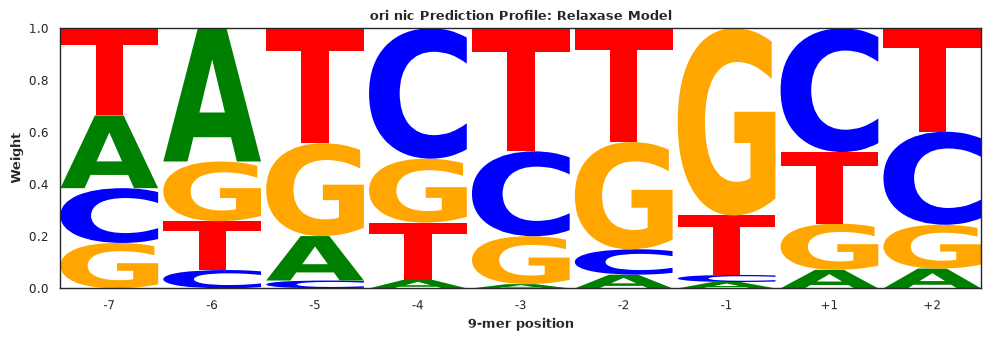

In [165]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import logomaker

x_val_dataset = torch.stack(
    [val_dataset[i][0] for i in range(len(val_dataset))]
)

oriT_predictor.eval()

with torch.inference_mode():
    inputs = x_val_dataset.to(device, non_blocking=True)
    head_logits = oriT_predictor(inputs)

    # Each head: (n_samples, 4); stack to (n_samples, 4, 9)
    probabilities = torch.stack(
        [torch.softmax(logits, dim=1) for logits in head_logits],
        dim=2,
    ).cpu().numpy()

# Average predicted base probabilities across validation samples:
# rows are positions, columns are A, C, G, T.
logo_df = pd.DataFrame(
    probabilities.mean(axis=0).T,
    columns=["A", "C", "G", "T"],
)


fig, ax = plt.subplots(figsize=(10, 3.5))

logomaker.Logo(
    logo_df,
    ax=ax,
    color_scheme="classic",
)

ax.set_title("ori nic Prediction Profile: Relaxase Model", weight="bold")
ax.set_xlabel("9-mer position")
ax.set_ylabel("Weight")

ax.set_xticks(range(9))
ax.set_xticklabels(["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"])

fig.tight_layout()
plt.show()

In [143]:
x_val_dataset = torch.stack(
    [x_val_dataset[i][0] for i in range(len(x_val_dataset))]
)

oriT_predictor.eval()

with torch.inference_mode():
    inputs = x_val_dataset.to(device, non_blocking=True)
    head_logits = oriT_predictor(inputs)

    # Each head: (n_samples, 4); stack to (n_samples, 4, 9)
    probabilities = torch.stack(
        [torch.softmax(logits, dim=1) for logits in head_logits],
        dim=2,
    ).cpu().numpy()

# Average predicted base probabilities across rep validation samples.
logo_df_rep = pd.DataFrame(
    probabilities.mean(axis=0).T,
    columns=["A", "C", "G", "T"],
)

fig, ax = plt.subplots(figsize=(10, 3.5))

logomaker.Logo(
    logo_df_rep,
    ax=ax,
    color_scheme="classic",
)

ax.set_title("ori nic Prediction Profile: Rep Model", weight="bold")
ax.set_xlabel("9-mer position")
ax.set_ylabel("Weight")
ax.set_xticks(range(9))
ax.set_xticklabels(["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"])

fig.tight_layout()
plt.show()

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x46 and 194x64)

In [29]:
x_val_dataset = torch.stack(
    [val_dataset[i][0] for i in range(len(val_dataset))]
)
y_val_dataset = torch.stack(
    [val_dataset[i][1] for i in range(len(val_dataset))]
)

oriT_predictor.eval()

with torch.inference_mode():
    inputs = x_val_dataset.to(device, non_blocking=True)
    targets = y_val_dataset.to(device, non_blocking=True)

    head_logits = oriT_predictor(inputs)
    logits = torch.stack(head_logits, dim=2)  # (samples, classes, positions)

    predictions = logits.argmax(dim=1)  # (samples, positions)
    overall_accuracy = predictions.eq(targets).float().mean().item() * 100
    overall_loss = loss_fn(logits, targets).item()

print(f"Validation accuracy: {overall_accuracy:.2f}%")
print(f"Validation loss: {overall_loss:.4f}")

Validation accuracy: 80.92%
Validation loss: 0.5962


In [146]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch

oriT_predictor.eval()

validation_sets = {
    "Rep": (x_val_rep_set, y_val_rep_set),
    "Relaxase": (x_val_relax_set, y_val_relax_set),
}

results = {}

with torch.inference_mode():
    for class_name, (x_val, y_val) in validation_sets.items():
        inputs = x_val.to(device, non_blocking=True)
        targets = y_val.to(device, non_blocking=True)

        # One logits tensor per head: each has shape (n_samples, n_classes)
        head_logits = oriT_predictor(inputs)

        # Shape: (n_samples, n_heads)
        predictions = torch.stack(
            [logits.argmax(dim=1) for logits in head_logits],
            dim=1,
        )

        # Compare each head with its matching target column
        head_accuracies = (
            predictions.eq(targets).float().mean(dim=0) * 100
        )

        results[class_name] = head_accuracies.cpu().numpy()


head_names = ["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]

# Rows are heads; columns are validation classes
accuracy_df = pd.DataFrame(
    results,
    index=head_names,
)

# Publication-style heatmap
sns.set_theme(style="white", font="DejaVu Sans", context="paper")
fig, ax = plt.subplots(figsize=(4.2, 5.0))

sns.heatmap(
    accuracy_df,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="viridis",
    vmin=0,
    vmax=100,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Accuracy (%)"},
)

ax.set(
    xlabel="Validation Set",
    ylabel="Position on 9-mer nic Site",
    title="Per-Position Accuracy",
)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
#fig.savefig("per_head_validation_accuracy.png", dpi=600, bbox_inches="tight")
plt.show()

RuntimeError: mat1 and mat2 shapes cannot be multiplied (43x397 and 194x64)

In [145]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import precision_score

oriT_predictor.eval()

validation_sets = {
    "Rep": (x_val_rep_set, y_val_rep_set),
    "Relaxase": (x_val_relax_set, y_val_relax_set),
}

results = {}

with torch.inference_mode():
    for class_name, (x_val, y_val) in validation_sets.items():
        inputs = x_val.to(device, non_blocking=True)
        targets = y_val.cpu().numpy()

        head_logits = oriT_predictor(inputs)
        predictions = torch.stack(
            [logits.argmax(dim=1) for logits in head_logits],
            dim=1,
        ).cpu().numpy()

        # Macro precision across classes, calculated separately for each head
        head_precisions = [
            precision_score(
                targets[:, head],
                predictions[:, head],
                average="macro",
                zero_division=0,
            ) * 100
            for head in range(targets.shape[1])
        ]

        results[class_name] = head_precisions

head_names = ["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]

precision_df = pd.DataFrame(results, index=head_names)

sns.set_theme(style="white", font="DejaVu Sans", context="paper")
fig, ax = plt.subplots(figsize=(4.2, 5.0))

sns.heatmap(
    precision_df,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="viridis",
    vmin=0,
    vmax=100,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Macro precision (%)"},
)

ax.set(
    xlabel="Validation Set",
    ylabel="Position on 9-mer nic Site",
    title="Per-Position Macro Precision",
)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
# fig.savefig("per_head_validation_macro_precision.png", dpi=600, bbox_inches="tight")
plt.show()

RuntimeError: mat1 and mat2 shapes cannot be multiplied (43x397 and 194x64)

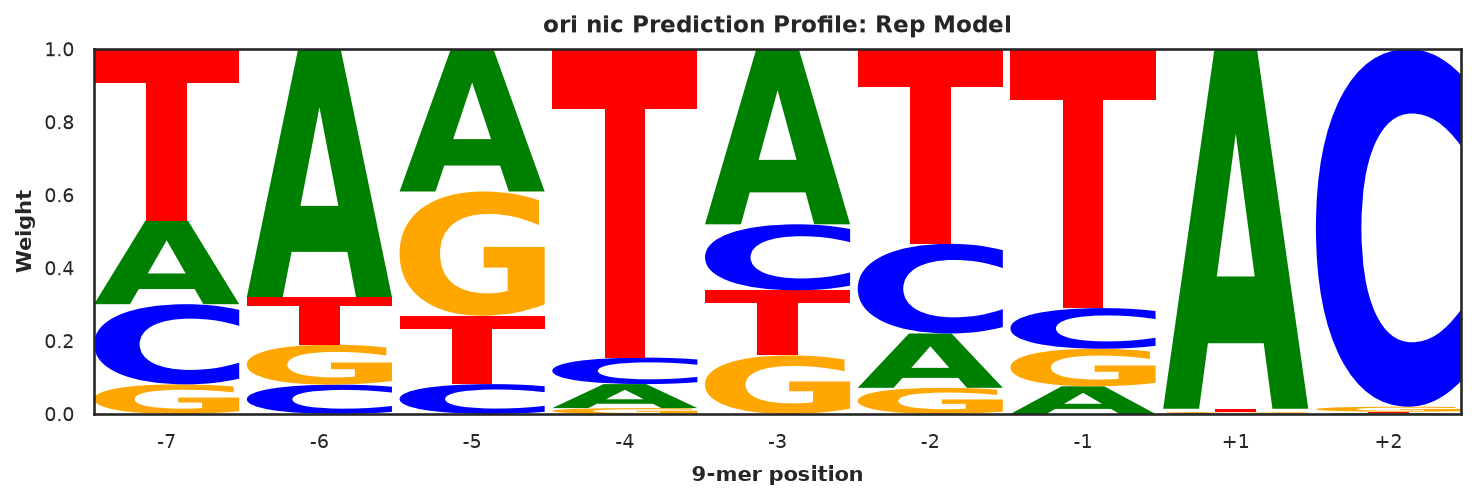

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import logomaker

x_val_dataset = torch.stack(
    [val_dataset[i][0] for i in range(len(val_dataset))]
)

oriT_predictor.eval()

with torch.inference_mode():
    inputs = x_val_dataset.to(device, non_blocking=True)
    head_logits = oriT_predictor(inputs)

    # Each head: (n_samples, 4); stack to (n_samples, 4, 9)
    probabilities = torch.stack(
        [torch.softmax(logits, dim=1) for logits in head_logits],
        dim=2,
    ).cpu().numpy()

# Rows are positions, columns are A, C, G, T.
logo_df = pd.DataFrame(
    probabilities.mean(axis=0).T,
    columns=["A", "C", "G", "T"],
    index=range(9),  # Integer index required by logomaker
)

sns.set_theme(style="white", context="notebook")

fig, ax = plt.subplots(figsize=(10, 3.5), dpi=150)

logomaker.Logo(
    logo_df,
    ax=ax,
    color_scheme="classic",
)

ax.set_title(
    "ori nic Prediction Profile: Rep Model",
    fontsize=11,
    fontweight="bold",
    pad=8,
)
ax.set_xlabel("9-mer position", fontsize=10, fontweight="bold", labelpad=6)
ax.set_ylabel("Weight", fontsize=10, fontweight="bold", labelpad=4)

ax.set_xticks(range(9))
ax.set_xticklabels(
    ["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"],
    fontsize=9,
)
ax.tick_params(axis="y", labelsize=9)

fig.tight_layout()
plt.show()

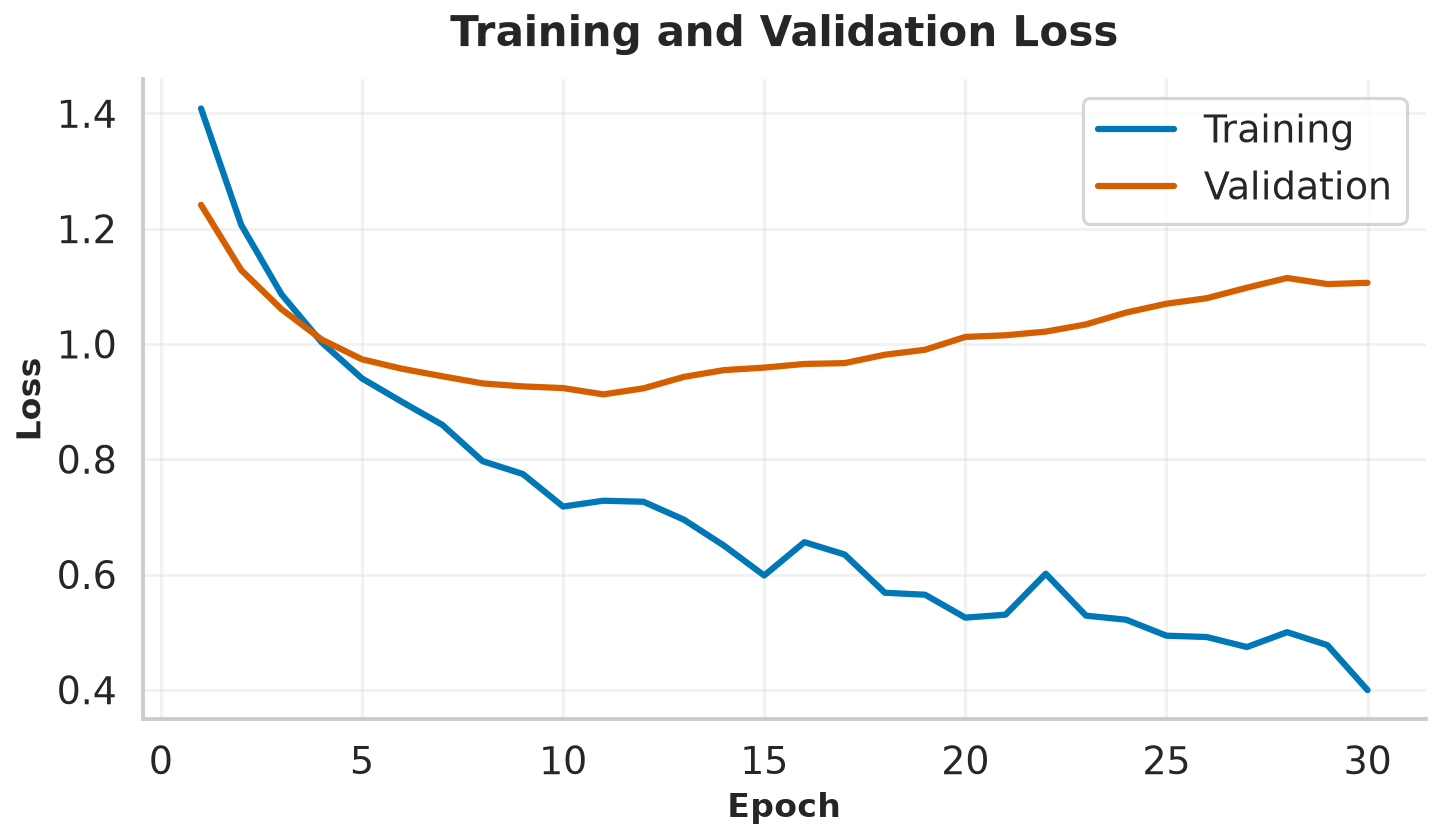

In [85]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plot_data = pd.DataFrame({
    "Epoch": list(range(1, len(loss_train) + 1)) * 2,
    "Loss": loss_train + loss_val,
    "Dataset": ["Training"] * len(loss_train) + ["Validation"] * len(loss_val),
})

sns.set_theme(style="whitegrid", context="talk", font_scale=1.1)

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

sns.lineplot(
    data=plot_data,
    x="Epoch",
    y="Loss",
    hue="Dataset",
    palette={"Training": "#0077B6", "Validation": "#D55E00"},
    linewidth=3,
    ax=ax,
)

ax.set_title("Training and Validation Loss", pad=16, fontsize=20)
ax.set_xlabel("Epoch", fontsize=16)
ax.set_ylabel("Loss", fontsize=16)
ax.legend(title=None, frameon=True, loc="best")
sns.despine()
fig.tight_layout()
plt.show()

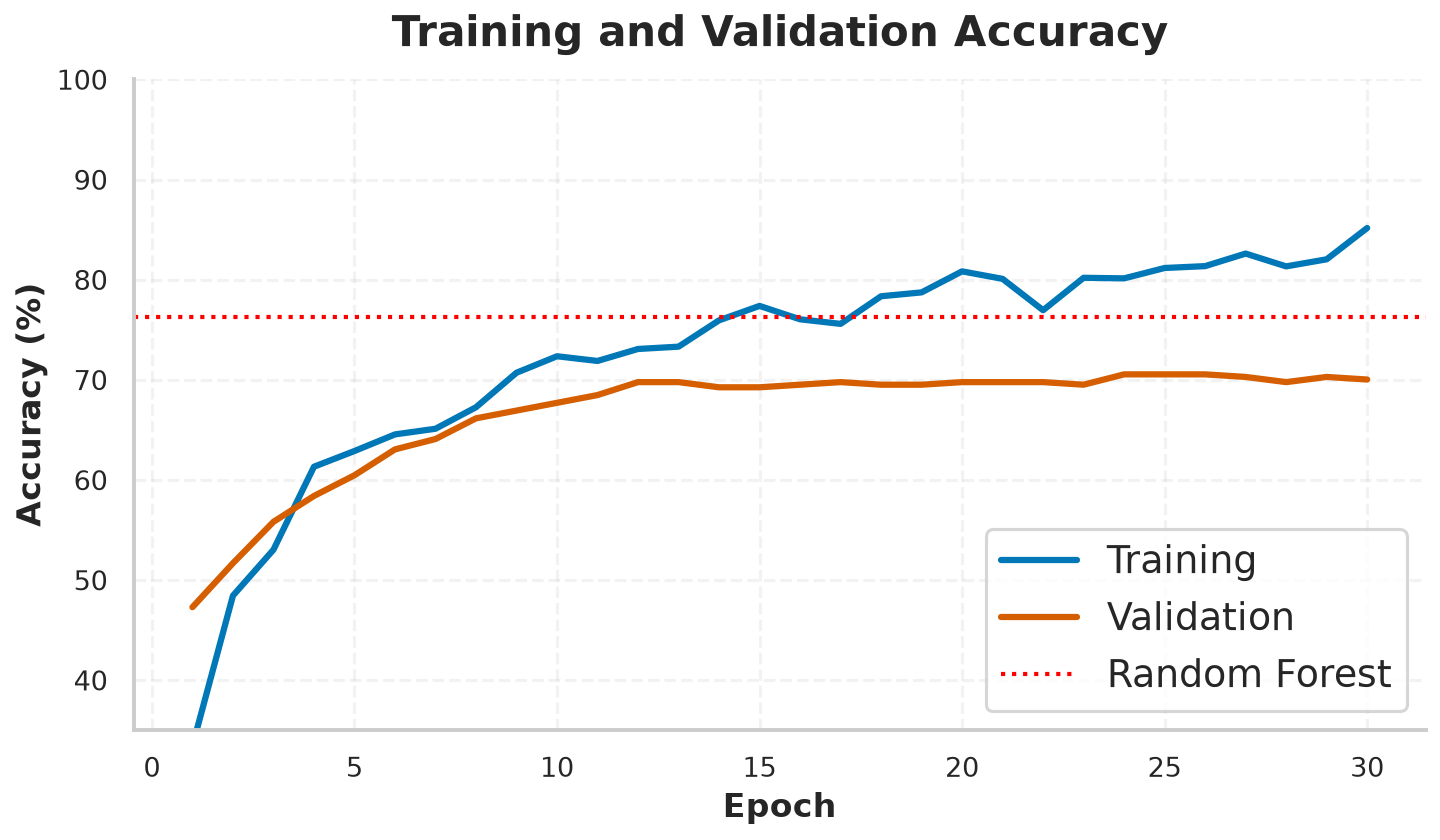

In [86]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plot_data = pd.DataFrame({
    "Epoch": list(range(1, len(acc) + 1)) * 2,
    "Accuracy": acc + acc_val,
    "Dataset": ["Training"] * len(acc) + ["Validation"] * len(acc_val),
})

sns.set_theme(
    style="whitegrid",
    context="talk",
    font_scale=1.1,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "grid.alpha": 0.25,
        "grid.linestyle": "--",
    },
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

sns.lineplot(
    data=plot_data,
    x="Epoch",
    y="Accuracy",
    hue="Dataset",
    style=None,
    palette={"Training": "#0077B6", "Validation": "#D55E00"},
    linewidth=3,
    ax=ax,
)

ax.axhline(y=76.3, color="red", linestyle=":", linewidth=2, label="Random Forest")

ax.set_title("Training and Validation Accuracy", pad=16, fontsize=20)
ax.set_xlabel("Epoch", fontsize=16)
ax.set_ylabel("Accuracy (%)", fontsize=16)
ax.set_ylim(35, 100)
ax.tick_params(axis="both", labelsize=13)
ax.legend(title=None, frameon=True, loc="lower right")
sns.despine()

fig.tight_layout()
# fig.savefig("accuracy_curve.pdf", bbox_inches="tight")
# fig.savefig("accuracy_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [81]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# X_train: (n_samples, n_features)
# y_train: (n_samples, n_heads)
# X_val:   (n_validation_samples, n_features)
# y_val:   (n_validation_samples, n_heads)

n_heads = y_train.shape[1]
head_accuracies = []
head_models = []

for head in range(n_heads):
    model = RandomForestClassifier(
        n_estimators=400,
        random_state=3242,
        n_jobs=-1,
        class_weight="balanced",
    )

    model.fit(X_train, y_train[:, head])
    predictions = model.predict(x_val_dataset)

    head_accuracies.append(accuracy_score(y_val_dataset[:, head], predictions))
    head_models.append(model)

for head, accuracy in enumerate(head_accuracies, start=1):
    print(f"Head {head} accuracy: {accuracy:.4f}")

print(f"Mean accuracy across heads: {np.mean(head_accuracies):.4f}")

Head 1 accuracy: 0.5930
Head 2 accuracy: 0.7907
Head 3 accuracy: 0.6512
Head 4 accuracy: 0.8721
Head 5 accuracy: 0.7326
Head 6 accuracy: 0.6279
Head 7 accuracy: 0.8953
Head 8 accuracy: 0.8605
Head 9 accuracy: 0.8488
Mean accuracy across heads: 0.7636


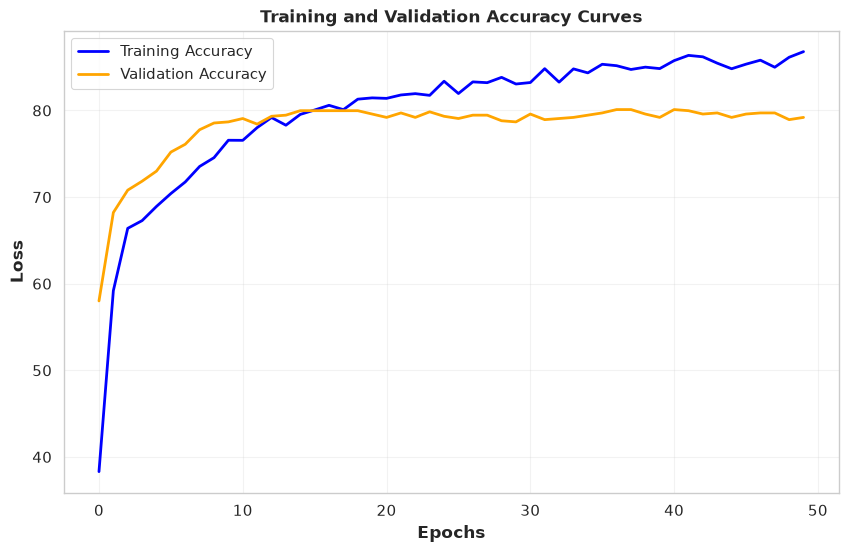

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(acc_val, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

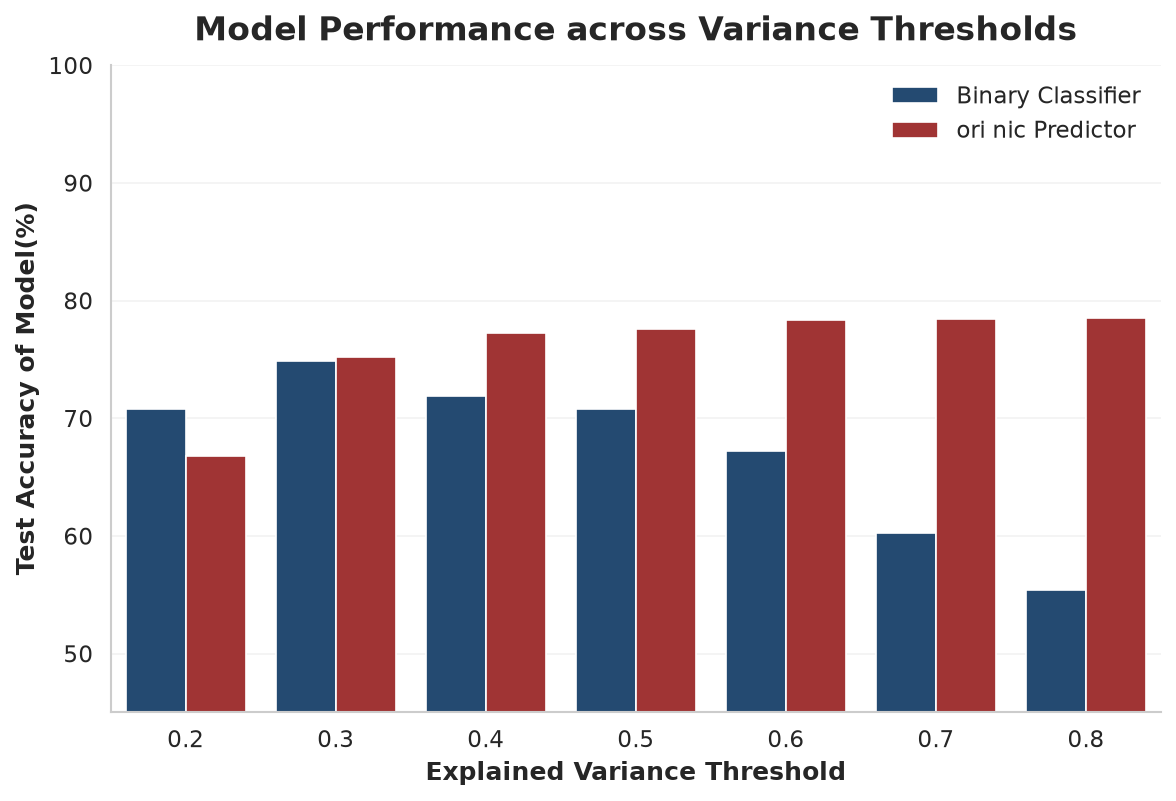

In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


plot_data = pd.DataFrame({
    "Position": [
        0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80,
        0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80,
    ],
    "Accuracy": [
        70.7602, 74.8538, 71.9298, 70.7602, 67.2512, 60.2339, 55.40937,
        66.7632, 75.1938, 77.2323, 77.6280, 78.3269, 78.4668, 78.50132,
    ],
    "Model": ["Binary Classifier"] * 7 + ["ori nic Predictor"] * 7,
})

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.25,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "grid.alpha": 0.25,
    },
)

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=150)

sns.barplot(
    data=plot_data,
    x="Position",
    y="Accuracy",
    hue="Model",
    palette=["#174A7E", "#B22222"],
    errorbar=None,
    ax=ax,
)

ax.set_title("Model Performance across Variance Thresholds", pad=12, fontsize=16)
ax.set_xlabel("Explained Variance Threshold")
ax.set_ylabel("Test Accuracy of Model(%)")
ax.set_ylim(45, 100)
ax.legend(title=None, frameon=False)
sns.despine(ax=ax)

fig.tight_layout()
# fig.savefig("classifier_accuracy_by_position.pdf", bbox_inches="tight")
# fig.savefig("classifier_accuracy_by_position.png", dpi=600, bbox_inches="tight")
plt.show()